# 03 — Timeline & Attack Reconstruction

Assemble the ordered sequence of the intrusion and render the incident figures.
Pairs with `cybersecurity/timeline.md` and the 7 lab answers.

In [1]:
import pandas as pd
packets = pd.read_csv('../data/processed/packets.csv', parse_dates=['time_utc'])
http    = pd.read_csv('../data/processed/http.csv', parse_dates=['time_utc'])
dns     = pd.read_csv('../data/processed/dns.csv', parse_dates=['time_utc'])

## Key events, in order

In [2]:
events = []
for _, r in http[http.kind=='request'].iterrows():
    stage = 'STAGE 1 (VBScript loader)' if r.uri=='/xlm.txt' else 'STAGE 2 (PowerShell/AsyncRAT)'
    events.append((r.time_utc, f"HTTP {r.method} {r.uri}  <- {stage}"))
for _, r in dns[dns.is_response==0].iterrows():
    events.append((r.time_utc, f"DNS query {r.qname}  <- DuckDNS C2 resolution"))
c2 = packets[(packets.dport==8808)|(packets.sport==8808)]
events.append((c2.time_utc.min(), 'AsyncRAT C2 channel opens (45.126.209.4:8808)'))
events.append((c2.time_utc.max(), 'AsyncRAT C2 channel last packet'))
tl = pd.DataFrame(sorted(events), columns=['time_utc','event'])
tl

,time_utc,event
0,2024-01-09 17:27:27.871,HTTP GET /xlm.txt <- STAGE 1 (VBScript loader)
1,2024-01-09 17:27:29.161,HTTP GET /mdm.jpg <- STAGE 2 (PowerShell/Asyn...
2,2024-01-09 17:29:48.927,DNS query madmrx.duckdns.org <- DuckDNS C2 re...
3,2024-01-09 17:29:49.269,AsyncRAT C2 channel opens (45.126.209.4:8808)
4,2024-01-09 17:40:13.947,AsyncRAT C2 channel last packet


## Render incident figures

figures -> C:\Users\moham\csfia2\visualizations



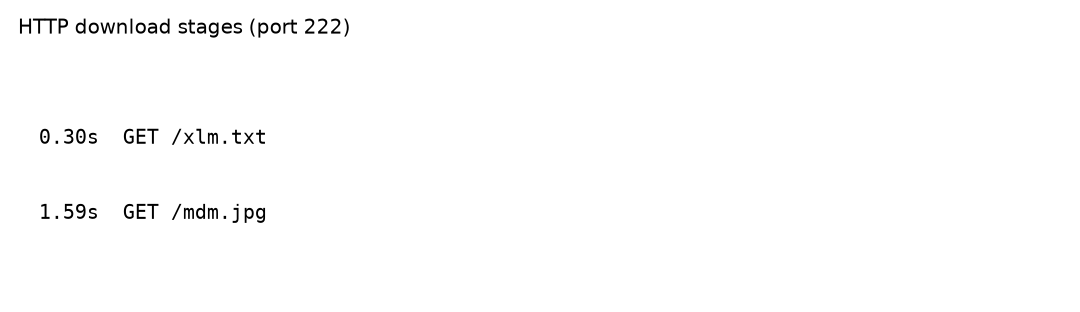

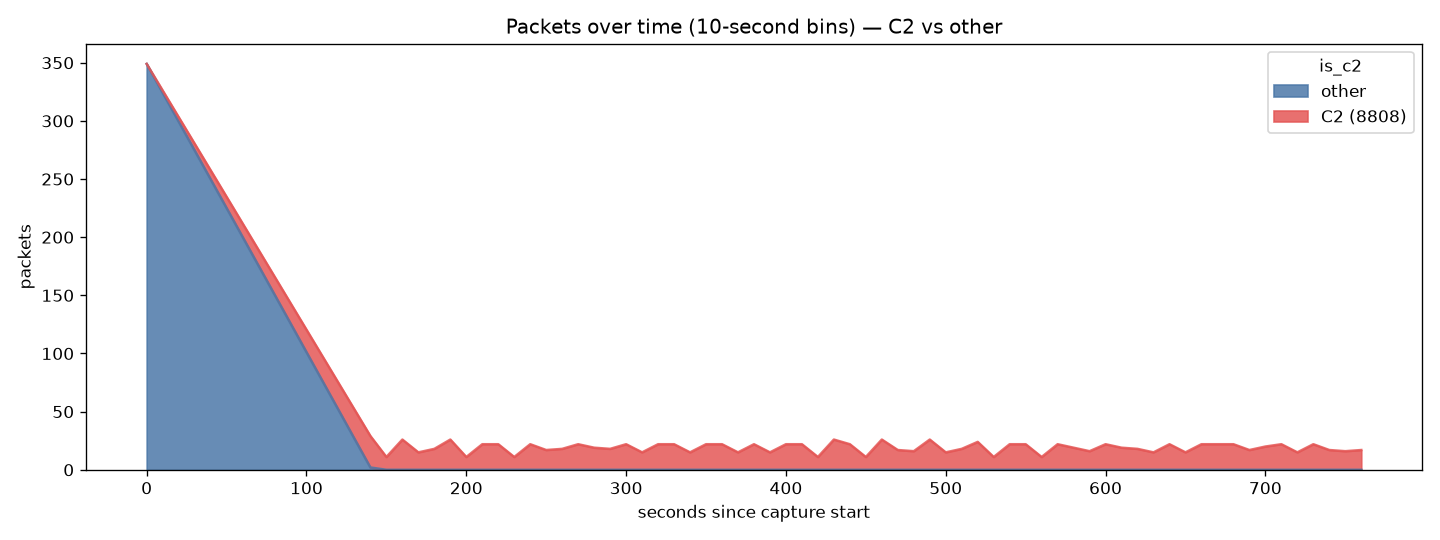

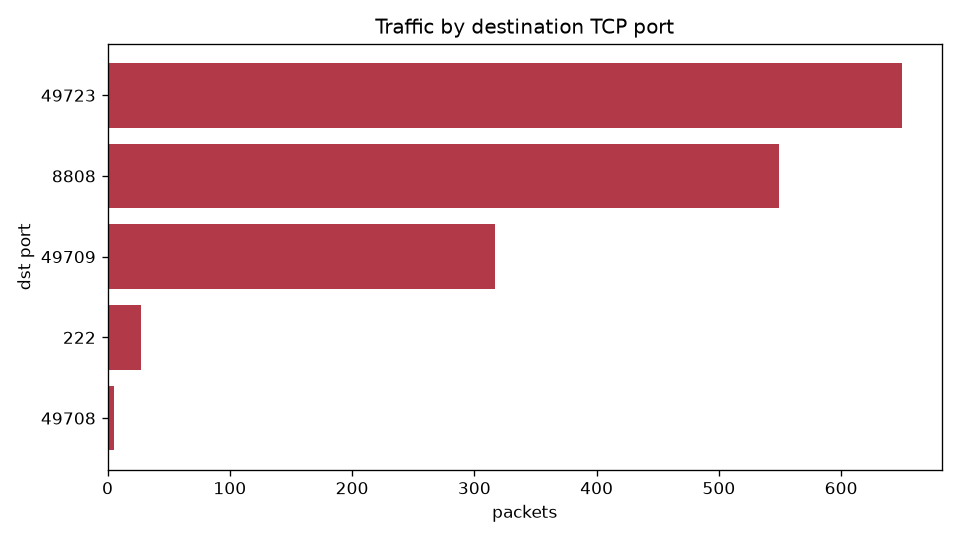

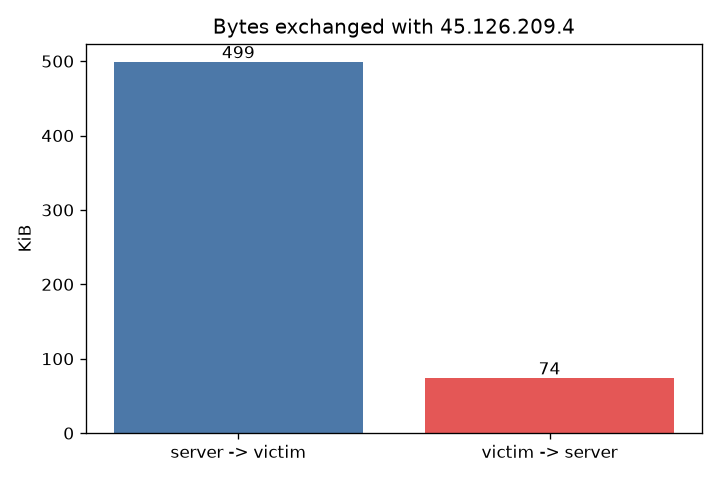

In [3]:
import sys, subprocess
print(subprocess.run([sys.executable, '../scripts/plots.py'], capture_output=True, text=True).stdout)
from IPython.display import Image, display
for f in ['http_stages.png','timeline.png','ports.png','bytes_direction.png']:
    display(Image('../visualizations/' + f))

## Answers to the 7 lab questions

| # | Answer |
|---|---|
| 1 | `http://45.126.209.4:222/xlm.txt` |
| 2 | ReliableSite.Net LLC |
| 3 | `1eb7b02e18f67420f42b1d94e74f3b6289d92672a0fb1786c30c03d68e81d798` |
| 4 | `Backdoor:MSIL/AsyncRat.A2786761` (AsyncRAT) |
| 5 | 2023-10-30 15:08 |
| 6 | `C:\Windows\Microsoft.NET\Framework\v4.0.30319\RegSvcs.exe` |
| 7 | Conted.ps1, Conted.bat, Conted.vbs |

See `cybersecurity/questions-answers.md` for the evidence behind each.